# Lab 05: The Dark Companion, Two Years Later

**ASTR 457, Fall 2026, posted Sat Oct 3, due Fri Oct 9 by Noon (extended) (fork → PR, as always)**

*Why this lab: every orbit in the literature, from Gaia's black-hole binaries to the planets David Charbonneau talked about on Tuesday, is a posterior distribution over six or seven parameters that nobody can write down in closed form. Sampling it, knowing when the sampler has actually converged, and turning the samples into a number with an honest error bar is the core professional skill of modern astrophysics, and the place where confident, fluent, wrong analyses are most common.*

On Day 1 you watched a star's radial velocity drift over ten nights and inferred an unseen companion from
the slope alone. This is that programme, two and a half years on. Every one of you has your own star:
`data/<your netid>.csv`, with columns `t_days` (time of each spectrum, from the first epoch), `rv_kms`
(the measured radial velocity) and `sigma_rv_kms` (the pipeline's per-epoch uncertainty). The star was
observed in three observing seasons over about 900 days, 28 to 44 epochs in all. It is a **single-lined
spectroscopic binary**: you see one star's lines, the companion contributes no light, and the visible star
follows a Keplerian orbit,

$$v_r(t) = \gamma + K\left[\cos\big(\nu(t) + \omega\big) + e\cos\omega\right],$$

with period $P$, semi-amplitude $K$, eccentricity $e$, argument of periastron $\omega$, a time of periastron
$T_p$, systemic velocity $\gamma$, and $\nu(t)$ the true anomaly (the angle around the orbit, which you get
from Kepler's equation; a function is provided). What you are really after is the **mass function**

$$f(M) = \frac{P K^3 (1 - e^2)^{3/2}}{2\pi G} = \frac{M_2^3 \sin^3 i}{(M_1 + M_2)^2},$$

a lower limit on the companion's mass, in solar masses. If it comes out above about $3\,M_\odot$ for a
Sun-like primary, you have a black hole candidate, the way Gaia BH1 was found (El-Badry et al. 2023, the Sep 8
colloquium). In the units of your file, $f(M) = 1.0361\times10^{-7}\,(1-e^2)^{3/2} K^3 P$ with $K$ in km/s
and $P$ in days.

I know your true $P$, $K$, $e$ and $f(M)$. You don't, your classmates' stars are different, and so is the
sampling. **One more thing I know and you don't: the quoted `sigma_rv_kms` is not the whole error.** Real
radial velocities carry an extra scatter, called jitter, from the star's own surface and from template
mismatch, and it is not in the pipeline number.

**How this is graded.** As always, on whether your answers are *right* and your uncertainties are *honest*:
your reported $P$, $K$, $e$ and $f(M)$ are compared to your truth in units of your own reported uncertainty.
Anti-sandbagging cap: your $\sigma_K$ may not exceed $3\times$ a reference posterior width I compute for your
dataset. Padded error bars lose points like overconfident ones.

**AI policy reminder.** Use whatever tools you like, including AI assistants, and document it in Part 4. You
may be selected to defend this lab orally; the defense is easy if you did the work.

Weights: Part 1 15%, Part 2 40%, Part 3 35%, Part 4 10%.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
from scipy.optimize import minimize
from astropy.timeseries import LombScargle

NETID = 'jhaff2'   # <-- set this
d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
t, rv, sig = d['t_days'], d['rv_kms'], d['sigma_rv_kms']
print(f"{t.size} epochs over {t.max() - t.min():.0f} days; median quoted error {np.median(sig):.2f} km/s")

def kepler_rv(t, P, K, e, omega, Tp, gamma):
    """Radial velocity of the visible star in a Keplerian orbit.
    P period [d], K semi-amplitude [km/s], e eccentricity, omega argument of periastron [rad],
    Tp a time of periastron [d], gamma systemic velocity [km/s]. Solves Kepler's equation by Newton iteration."""
    M = 2. * np.pi * ((t - Tp) / P % 1.0)            # mean anomaly
    E = M.copy()                                     # eccentric anomaly
    for _ in range(30):
        E = E - (E - e * np.sin(E) - M) / (1. - e * np.cos(E))
    nu = 2. * np.arctan2(np.sqrt(1. + e) * np.sin(E / 2.), np.sqrt(1. - e) * np.cos(E / 2.))   # true anomaly
    return gamma + K * (np.cos(nu + omega) + e * np.cos(omega))

def mass_function(P, K, e):
    """f(M) in solar masses, for P in days and K in km/s."""
    return 1.0361e-7 * (1. - e**2)**1.5 * K**3 * P



29 epochs over 873 days; median quoted error 1.88 km/s


## Part 1: Look first, then find the period (15%)

Plot the radial velocities against time with their error bars. Then find candidate orbital periods with a
Lomb-Scargle periodogram of the velocities (`astropy.timeseries.LombScargle`, Day 7's periodogram, formally
taught on Oct 20/22; for now it is a tool that ranks periods). Plot the periodogram. Then, for the best two or
three candidate periods, phase-fold the data and look.

Answer, in a few sentences: how many candidate periods are plausible from the periodogram alone, and why does
a Lomb-Scargle periodogram (which fits a *sinusoid*) not settle the question for an eccentric orbit? What
feature of the sampling (look at the gaps) produces the other peaks?


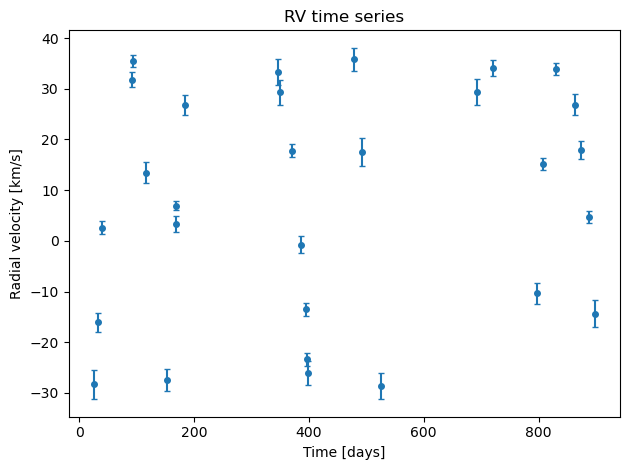

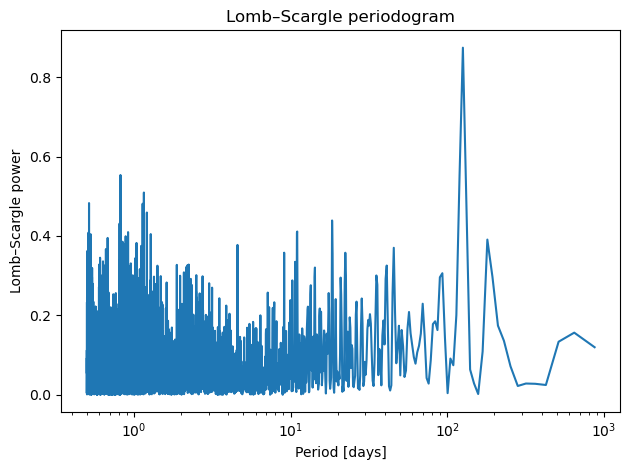

Top candidate periods [days]: [125.89269742   0.82028306 119.85918994]


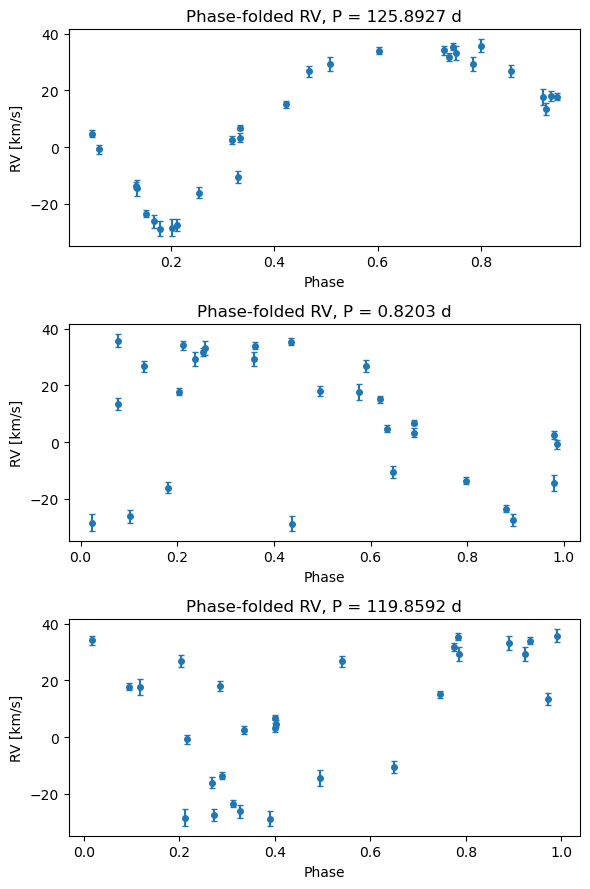

In [2]:
plt.errorbar(t, rv, yerr=sig, fmt='o', ms=4, capsize=2)
plt.xlabel("Time [days]")
plt.ylabel("Radial velocity [km/s]")
plt.title("RV time series")
plt.tight_layout()
plt.show()

# ---------- Lomb–Scargle periodogram ----------
# Choose a reasonable frequency grid
baseline = t.max() - t.min()
min_period = 0.5          # days, adjust as needed
max_period = baseline     # up to full baseline
min_freq = 1.0 / max_period
max_freq = 1.0 / min_period

freq = np.linspace(min_freq, max_freq, 5000)
ls = LombScargle(t, rv, sig)
power = ls.power(freq)

plt.plot(1.0 / freq, power)
plt.xlabel("Period [days]")
plt.ylabel("Lomb–Scargle power")
plt.title("Lomb–Scargle periodogram")
plt.xscale("log")
plt.tight_layout()
plt.show()

# ---------- Pick top candidate periods ----------
# Sort by power, take top N
N = 3
idx_sorted = np.argsort(power)[::-1]
best_freqs = freq[idx_sorted[:N]]
best_periods = 1.0 / best_freqs
print("Top candidate periods [days]:", best_periods)

# ---------- Phase-folded plots ----------
fig, axes = plt.subplots(N, 1, figsize=(6, 3 * N), sharex=False)
if N == 1:
    axes = [axes]

for ax, P in zip(axes, best_periods):
    phase = ((t / P) % 1.0)
    # sort by phase for nicer plotting
    order = np.argsort(phase)
    phase_sorted = phase[order]
    rv_sorted = rv[order]
    sig_sorted = sig[order]

    ax.errorbar(phase_sorted, rv_sorted, yerr=sig_sorted, fmt='o', ms=4, capsize=2)
    ax.set_xlabel("Phase")
    ax.set_ylabel("RV [km/s]")
    ax.set_title(f"Phase-folded RV, P = {P:.4f} d")

plt.tight_layout()
plt.show()

**ANSWER (a few sentences):**

There appears to be one really clear candidate, at period 125 days or so, and then one maybe slightly at period 0f 0.8 days. Logically, I'm going to rule out that second one. The third candidiare looks a lot more abstract, so I don't think that one. 
There's maybe 3 or really 2 good peaks in the periodogram. Only 1 looks really really good. It would look perfect if the orbit was a perfect circle and could be modeled by a sin graph, but as it cannot be, the peaks have a lot of noise and look messy. All of the other noise comes from the epochs and sampling and it gets more chaotic as you get to smaller periods, which cannot be trusted. 

## Part 2: Sample the posterior (40%)

Fit the six orbital parameters **plus a jitter term** $s$ with `emcee`. The likelihood for epoch $i$ is
Gaussian with variance $\sigma_i^2 + s^2$; write it out (including the $\log$ of the variance, which is not a
constant once $s$ is a parameter). You will need to:

1. **Write the log-likelihood, log-prior and log-posterior.** State every prior and justify it in one line
   each. Two traps: $\omega$ and $T_p$ are periodic ($T_p$ is only defined modulo $P$), and `emcee` does not
   wrap angles, so a hard prior wall at $0$ or $2\pi$ can cut a posterior mode in half. Either bound each of
   them within half a period of your starting value, or reparameterize with $\sqrt{e}\cos\omega$ and
   $\sqrt{e}\sin\omega$ (which also gives a uniform prior on $e$ without a wall at zero). Jitter is
   positive: sample $\ln s$.
2. **Start the walkers sensibly.** A maximum-likelihood fit from each plausible Part 1 period, with several
   starting $\omega$ and $T_p$ each, then compare the log-likelihoods; start the walkers in a small ball
   around the best one. That comparison is the check: report the log-likelihood of the runner-up.
3. **Run, then decide when it is done.** Compute the integrated autocorrelation time $\tau$ for every
   parameter (`sampler.get_autocorr_time`). Here $\tau$ is about 50 to 100 steps, so 64 walkers for
   10,000 steps is plenty (a few minutes) and `emcee`'s own rule is a chain longer than $50\tau$. A
   common choice is to discard a few $\tau$ as burn-in and thin by about $\tau/2$; say what you chose
   and why. Plot the chains. If $\tau$ cannot be estimated, your chain is too short; say so and fix it.
4. **Corner plot.** Which parameters are correlated, and why physically?
5. **Report** $P$, $K$, $e$, $\gamma$, the jitter $s$, and $f(M)$, each as a median and 68% interval.
   **$f(M)$ is computed for every posterior sample**, not from the medians of $P$, $K$ and $e$; explain in
   one sentence why that matters.
6. **Posterior predictive check.** Draw a few hundred orbits from the posterior and plot them over the data,
   phase-folded at the median period. Plot the normalized residuals with the *total* error bar
   $\sqrt{\sigma_i^2 + s^2}$. Is what is left noise?

**FINAL ANSWER:** P = 126.91015 +/- 0.16090, K = 31.744 +/- 0.822, e = 0.312 +/- 0.022, f(M) = 0.3604 +/- 0.0265

**Black-hole candidate?** *one sentence*
No, the mass is too low for it to be a blackhole

In [3]:
from scipy.signal import find_peaks

np.random.seed(42)
labels = ["P", "K", "h", "k", "Tp", "gamma", "ln s"]
ndim, nwalkers = 7, 64
P_MAX = baseline            # same range as the Lomb-Scargle search

# theta = [P, K, h, k, Tp, gamma, ln s],  h = sqrt(e) cos(omega),  k = sqrt(e) sin(omega)
# Epoch i is Gaussian with variance V_i = sigma_i^2 + s^2:
#   ln L = -1/2 * sum_i [ (v_i - v_model(t_i))^2 / V_i + ln(2 pi V_i) ]
# ln(2 pi) is constant and dropped. ln V_i is NOT constant because s is a parameter, so it is kept.

def unpack_params(theta):
    P, K, h, k, Tp, gamma, ln_s = theta
    return P, K, h*h + k*k, np.arctan2(k, h), Tp, gamma, np.exp(ln_s)

def log_likelihood(theta):
    P, K, e, omega, Tp, gamma, s = unpack_params(theta)
    if e >= 1.0:
        return -np.inf
    model = kepler_rv(t, P, K, e, omega, Tp, gamma)
    var = sig**2 + s**2
    ll = -0.5 * np.sum((rv - model)**2 / var + np.log(var))
    return ll if np.isfinite(ll) else -np.inf

Tp_ref = None   # set after the ML step (Cell 2), before the first log_posterior call

def log_prior(theta):
    P, K, h, k, Tp, gamma, ln_s = theta
    # P: uniform on (0.5, P_MAX) d. No preferred scale inside the range searched in Part 1.
    if not (0.5 < P < P_MAX):                           return -np.inf
    # K: uniform on (0, 200) km/s. Positive amplitude, generous upper bound.
    if not (0.0 < K < 200.0):                           return -np.inf
    # (h, k) uniform on the unit disk -> e = h^2 + k^2 < 1, uniform in e, no wall at e=0, omega periodic by construction.
    if h*h + k*k >= 1.0:                                return -np.inf
    # Tp: uniform within half a period of Tp_ref. Tp is only defined modulo P, so exactly one cycle.
    if not (abs(Tp - Tp_ref) < 0.5 * P):                return -np.inf
    # gamma: uniform within 50 km/s of the data range. The systemic velocity must be near the data.
    if not (rv.min() - 50.0 < gamma < rv.max() + 50.0): return -np.inf
    # ln s: uniform on (-10, 3). Scale-invariant for a positive scatter, and wide.
    if not (-10.0 < ln_s < 3.0):                        return -np.inf
    return 0.0

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    ll = log_likelihood(theta)
    return lp + ll if np.isfinite(ll) else -np.inf

In [4]:
# Candidates: three DISTINCT periodogram peaks, plus P/2 and 2P of the best (harmonic check)
pk, _ = find_peaks(power)
top = pk[np.argsort(power[pk])[::-1][:3]]
cands = list(1.0 / freq[top])
cands += [cands[0] / 2.0, cands[0] * 2.0]
cands = [P for P in cands if 0.5 < P < P_MAX]
print("Candidate periods [d]:", np.round(cands, 4))

def neg_loglike_ml(params, P):
    K, h, k, Tp, gamma, ln_s = params          # P fixed
    if K <= 0:
        return np.inf
    ll = log_likelihood(np.array([P, K, h, k, Tp, gamma, ln_s]))
    return -ll if np.isfinite(ll) else np.inf

nm_opts = {'maxiter': 5000, 'maxfev': 10000, 'xatol': 1e-6, 'fatol': 1e-8}
omega_guesses = np.linspace(0, 2*np.pi, 5, endpoint=False)
e_guesses = [0.1, 0.5]
K_start = (rv.max() - rv.min()) / 2.0

ml_results = []
for P in cands:
    Tp_guesses = t.min() + np.linspace(0, 1, 5, endpoint=False) * P   # one full cycle of phase
    best_fun, best_x = np.inf, None
    for e0 in e_guesses:
        for omg in omega_guesses:
            for Tp_start in Tp_guesses:
                x0 = np.array([K_start, np.sqrt(e0)*np.cos(omg), np.sqrt(e0)*np.sin(omg),
                               Tp_start, np.median(rv), np.log(np.median(sig))])
                res = minimize(neg_loglike_ml, x0, args=(P,), method='Nelder-Mead', options=nm_opts)
                if res.fun < best_fun:
                    best_fun, best_x = res.fun, res.x
    ml_results.append((P, best_fun, best_x))

ml_results.sort(key=lambda r: r[1])
print("\n=== ML comparison (fixed P from the periodogram) ===")
for P, f, _ in ml_results:
    print(f"P = {P:10.5f} d   log-likelihood = {-f:9.2f}")
best_P, best_fun, best_x = ml_results[0]
runner_P, runner_fun, _ = ml_results[1]
print(f"Best: {best_P:.5f} d (lnL = {-best_fun:.2f});  runner-up: {runner_P:.5f} d "
      f"(lnL = {-runner_fun:.2f});  Delta lnL = {runner_fun - best_fun:.2f}")

# Polish with P free
x_best = np.concatenate([[best_P], best_x])
def neg_ll_free(theta):
    if not (0.5 < theta[0] < P_MAX) or theta[1] <= 0:
        return np.inf
    ll = log_likelihood(theta)
    return -ll if np.isfinite(ll) else np.inf
pol = minimize(neg_ll_free, x_best, method='Nelder-Mead', options=nm_opts)
x_ml = pol.x if pol.fun <= neg_ll_free(x_best) else x_best
print(f"After freeing P: P = {x_ml[0]:.5f} d, lnL = {log_likelihood(x_ml):.2f}")

P0, K0, h0, k0, Tp0, gamma0, ln_s0 = x_ml
Tp_ref = t.mean() + ((Tp0 - t.mean() + P0/2) % P0) - P0/2     # wrap Tp into one cycle
p0 = np.array([P0, K0, h0, k0, Tp_ref, gamma0, ln_s0])
assert np.isfinite(log_posterior(p0)), "ML solution is outside the prior; check bounds"

# Small ball, scaled per parameter; redraw any walker that lands outside the prior
scales = np.array([1e-4*P0, 1e-3*abs(K0), 1e-3, 1e-3, 1e-3*P0, 1e-3*abs(gamma0) + 1e-3, 1e-2])
walkers = []
while len(walkers) < nwalkers:
    trial = p0 + scales * np.random.randn(ndim)
    if np.isfinite(log_posterior(trial)):
        walkers.append(trial)
p0_walkers = np.array(walkers)

Candidate periods [d]: [125.8927   0.8203   1.1574  62.9463 251.7854]

=== ML comparison (fixed P from the periodogram) ===
P =  125.89270 d   log-likelihood =    -52.25
P =   62.94635 d   log-likelihood =    -93.20
P =    1.15738 d   log-likelihood =    -95.25
P =    0.82028 d   log-likelihood =    -96.77
P =  251.78539 d   log-likelihood =    -98.05
Best: 125.89270 d (lnL = -52.25);  runner-up: 62.94635 d (lnL = -93.20);  Delta lnL = 40.95
After freeing P: P = 126.91546 d, lnL = -38.68


You must install the tqdm library to use progress indicators with emcee



tau: {'P': np.float64(74.6), 'K': np.float64(70.5), 'h': np.float64(76.4), 'k': np.float64(75.4), 'Tp': np.float64(75.6), 'gamma': np.float64(74.6), 'ln s': np.float64(90.2)}
production steps / tau_max = 110.9  (rule: > 50)
burn-in / tau_max = 22.2  (want >= 3)
Mean acceptance fraction: 0.486
Using burn-in = 2000 steps, thin = 45 (~tau/2)
Number of posterior samples: 14208


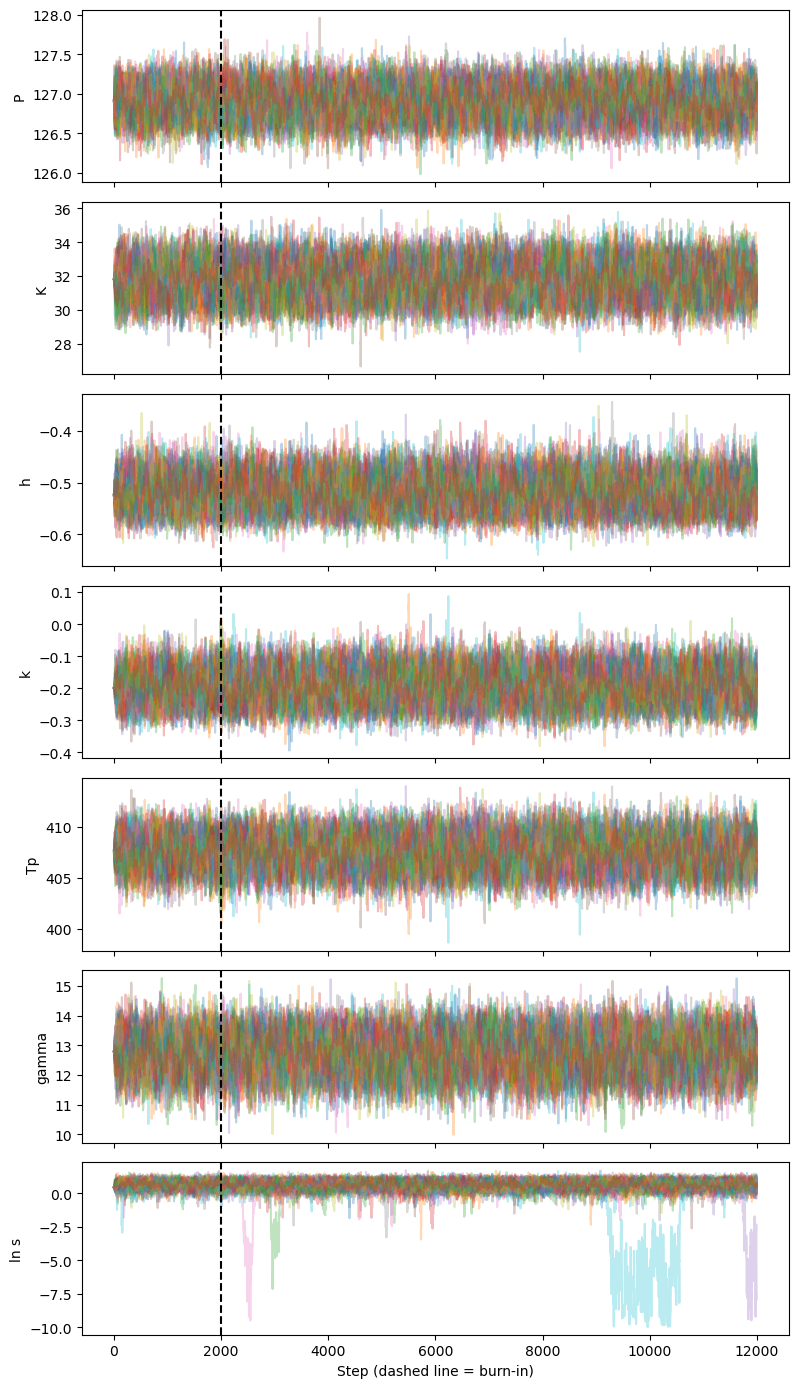

In [5]:
burnin = 2000                     # confirm against the chain plot; also want >= 3 tau
n_steps = 12000                   # burn-in + 10,000 production steps
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)
sampler.run_mcmc(p0_walkers, n_steps, progress=True)

def check_tau():
    tau = sampler.get_autocorr_time(discard=burnin, tol=0)   # tol=0 always returns an estimate
    return tau, np.max(tau), sampler.iteration - burnin

tau, tau_max, n_prod = check_tau()
extensions = 0
while n_prod < 50 * tau_max and extensions < 5:               # emcee's rule: chain > 50 tau
    print(f"Chain too short (N/tau_max = {n_prod/tau_max:.1f} < 50); extending by 5000 steps")
    sampler.run_mcmc(None, 5000, progress=True)
    tau, tau_max, n_prod = check_tau()
    extensions += 1

print("\ntau:", dict(zip(labels, np.round(tau, 1))))
print(f"production steps / tau_max = {n_prod / tau_max:.1f}  (rule: > 50)")
print(f"burn-in / tau_max = {burnin / tau_max:.1f}  (want >= 3)")
print("Mean acceptance fraction:", round(float(np.mean(sampler.acceptance_fraction)), 3))

thin = max(1, int(tau_max / 2))
print(f"Using burn-in = {burnin} steps, thin = {thin} (~tau/2)")

flat_samples = sampler.get_chain(discard=burnin, thin=thin, flat=True)
lp_flat = sampler.get_log_prob(discard=burnin, thin=thin, flat=True)
print("Number of posterior samples:", flat_samples.shape[0])

chains = sampler.get_chain()
fig, axes = plt.subplots(ndim, 1, figsize=(8, 2*ndim), sharex=True)
for i in range(ndim):
    axes[i].plot(chains[:, :, i], alpha=0.3)
    axes[i].axvline(burnin, color='k', ls='--')
    axes[i].set_ylabel(labels[i])
axes[-1].set_xlabel("Step (dashed line = burn-in)")
plt.tight_layout()
plt.show()

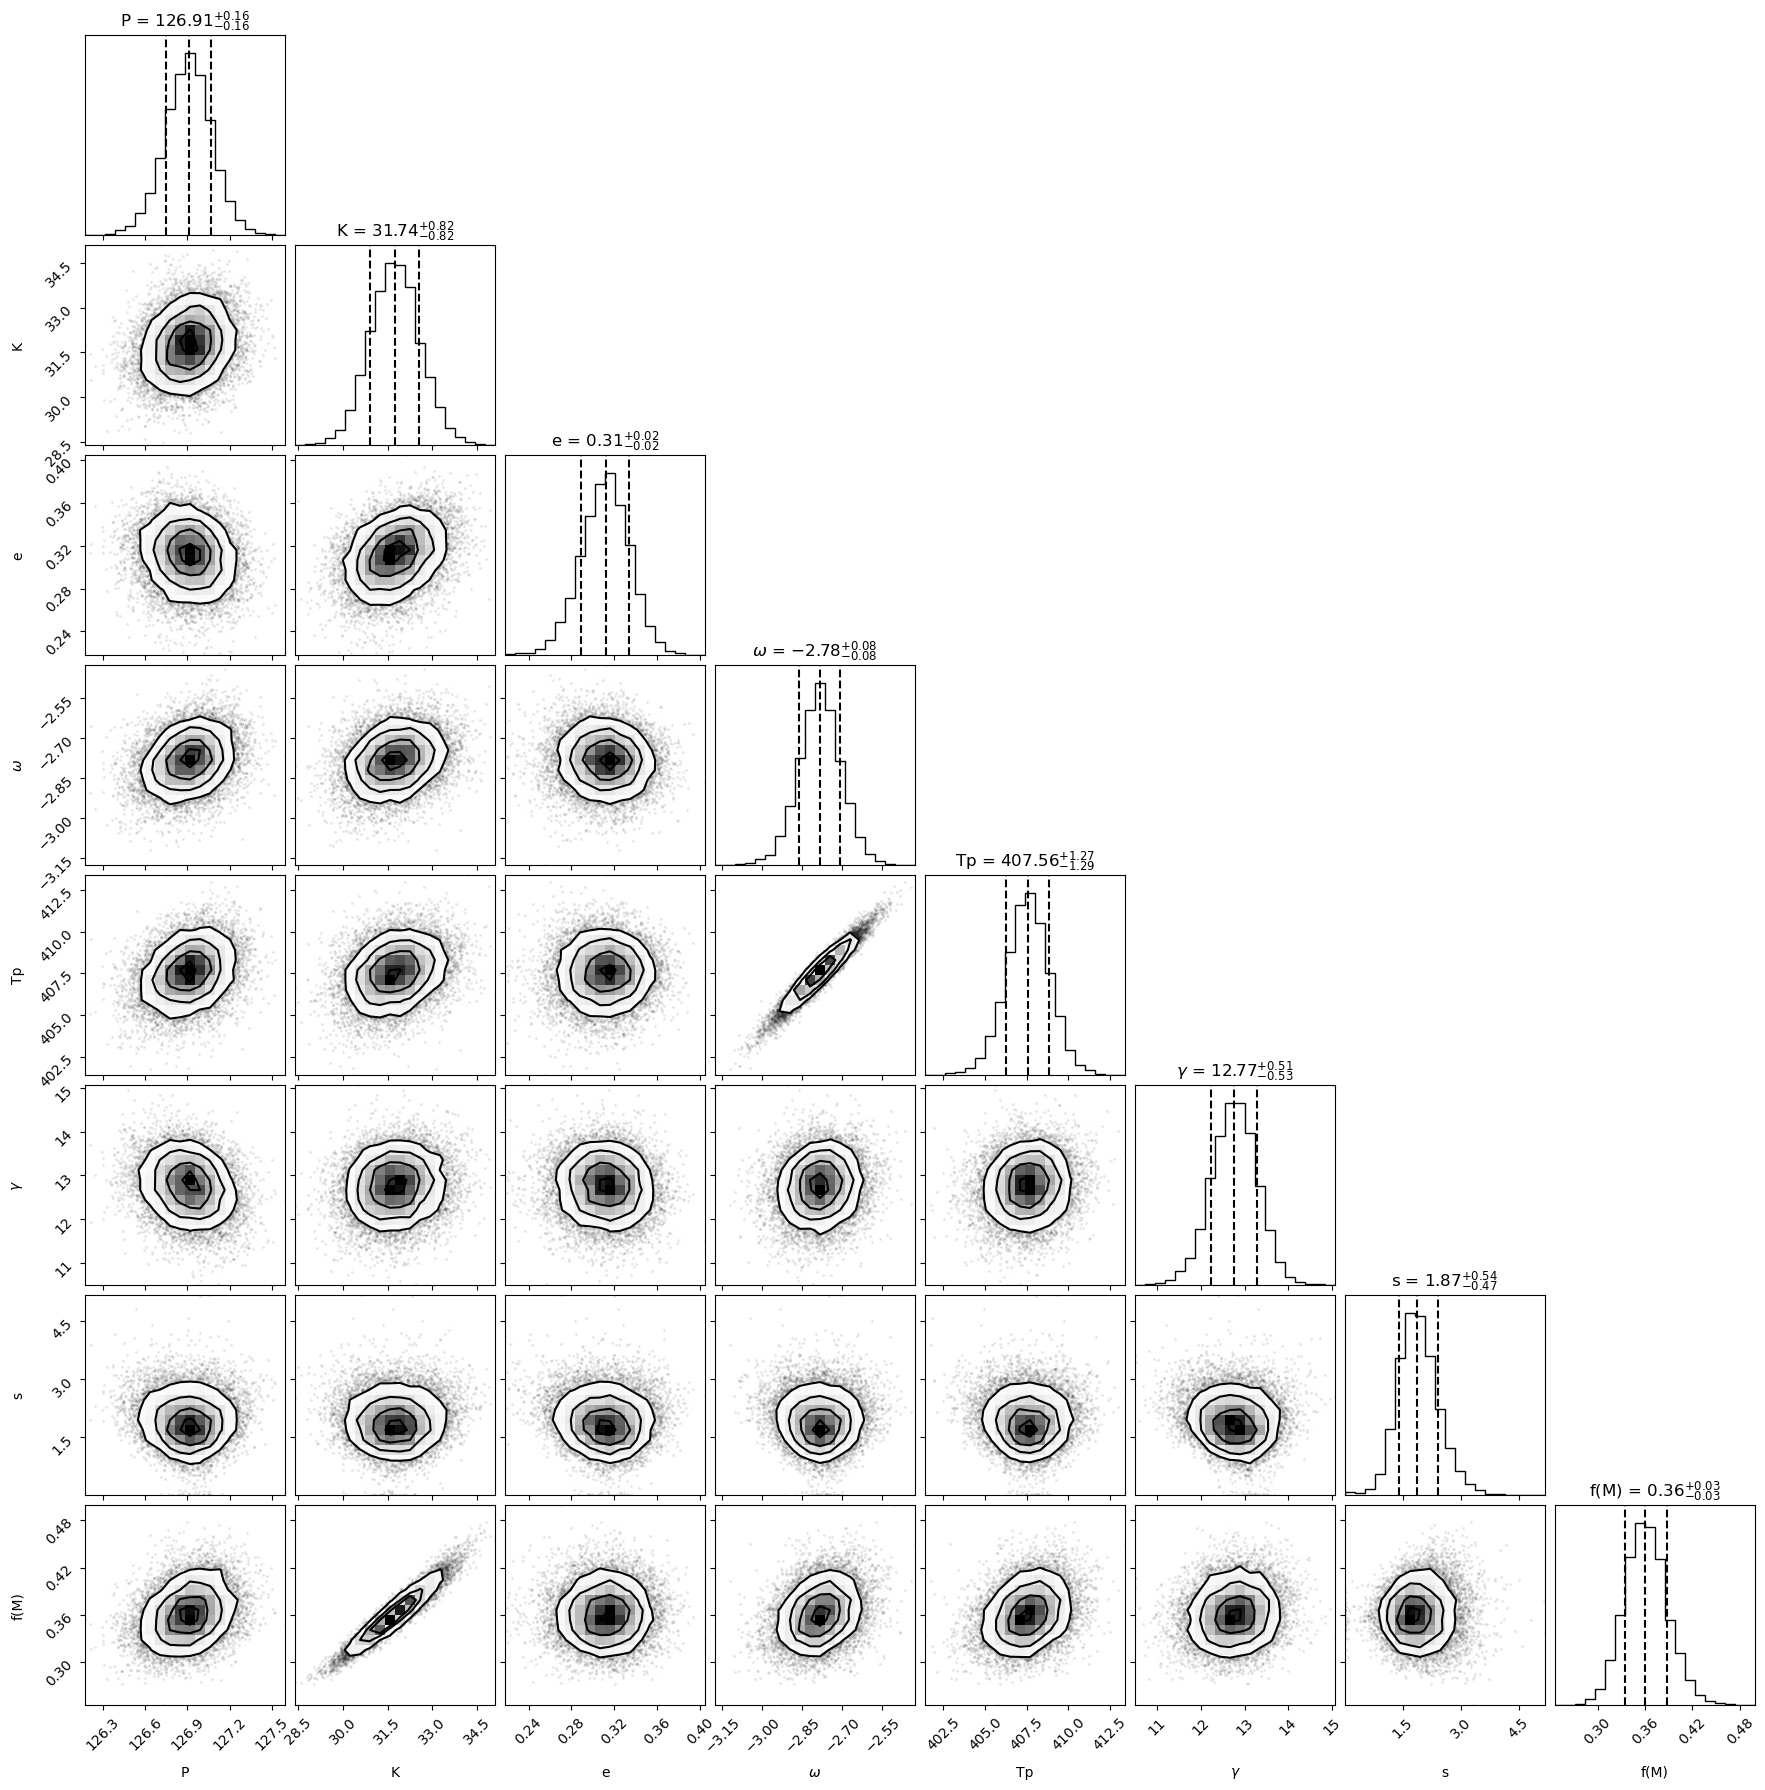

In [6]:
P_samp, K_samp, h_samp, k_samp, Tp_samp, gamma_samp, lns_samp = flat_samples.T
e_samp = h_samp**2 + k_samp**2
s_samp = np.exp(lns_samp)
fM_samp = mass_function(P_samp, K_samp, e_samp)               # per sample, not from medians

imap = np.argmax(lp_flat)                                     # max-posterior sample = one real orbit
P_b, K_b, h_b, k_b, Tp_b, g_b, lns_b = flat_samples[imap]
e_b, om_b, s_b = h_b**2 + k_b**2, np.arctan2(k_b, h_b), np.exp(lns_b)

omega_samp = np.arctan2(k_samp, h_samp)
omega_samp = (omega_samp - om_b + np.pi) % (2*np.pi) - np.pi + om_b   # unwrap around MAP

corner_data = np.column_stack([P_samp, K_samp, e_samp, omega_samp, Tp_samp, gamma_samp, s_samp, fM_samp])
corner.corner(corner_data, labels=["P", "K", "e", r"$\omega$", "Tp", r"$\gamma$", "s", "f(M)"],
              show_titles=True, quantiles=[0.16, 0.5, 0.84])
plt.show()

In [7]:
def median_68(x):
    med = np.median(x)
    lo, hi = np.percentile(x, [16, 84])
    return med, med - lo, hi - med

P_med, P_lo, P_hi = median_68(P_samp)
K_med, K_lo, K_hi = median_68(K_samp)
e_med, e_lo, e_hi = median_68(e_samp)
g_med, g_lo, g_hi = median_68(gamma_samp)
s_med, s_lo, s_hi = median_68(s_samp)
fM_med, fM_lo, fM_hi = median_68(fM_samp)

print("=== Posterior summaries (median +hi -lo, 68%) ===")
print(f"P     = {P_med:.5f} +{P_hi:.5f} -{P_lo:.5f} d")
print(f"K     = {K_med:.3f} +{K_hi:.3f} -{K_lo:.3f} km/s")
print(f"e     = {e_med:.3f} +{e_hi:.3f} -{e_lo:.3f}")
print(f"gamma = {g_med:.3f} +{g_hi:.3f} -{g_lo:.3f} km/s")
print(f"s     = {s_med:.3f} +{s_hi:.3f} -{s_lo:.3f} km/s")
print(f"f(M)  = {fM_med:.4f} +{fM_hi:.4f} -{fM_lo:.4f} Msun")
print(f"sigma_K = {(K_lo + K_hi)/2:.3f} km/s  <- check against the 3x reference-width cap")

=== Posterior summaries (median +hi -lo, 68%) ===
P     = 126.91015 +0.15695 -0.16484 d
K     = 31.744 +0.823 -0.822 km/s
e     = 0.312 +0.022 -0.023
gamma = 12.767 +0.508 -0.528 km/s
s     = 1.866 +0.540 -0.467 km/s
f(M)  = 0.3604 +0.0272 -0.0257 Msun
sigma_K = 0.822 km/s  <- check against the 3x reference-width cap


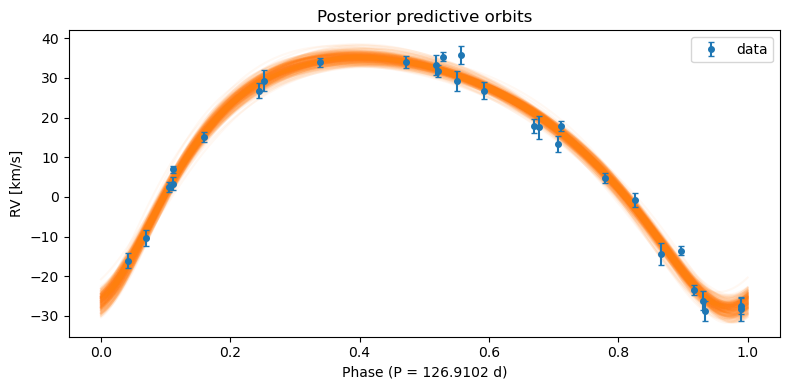

Residuals: std = 0.91, chi2 = 24.0 for dof = 22


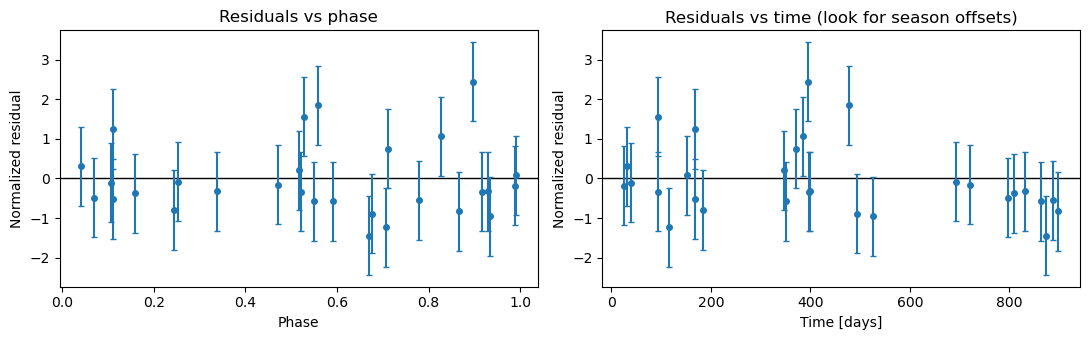

In [8]:
phase = ((t - Tp_b) / P_med) % 1.0            # fold at the median period
phg = np.linspace(0, 1, 400)
tg = phg * P_med + Tp_b

idx_draw = np.random.choice(flat_samples.shape[0], 300, replace=False)
plt.figure(figsize=(8, 4))
for idx in idx_draw:
    P_d, K_d, h_d, k_d, Tp_d, g_d, _ = flat_samples[idx]
    m = kepler_rv(tg, P_d, K_d, h_d**2 + k_d**2, np.arctan2(k_d, h_d), Tp_d, g_d)
    plt.plot(phg, m, 'C1', alpha=0.05)
plt.errorbar(phase, rv, yerr=sig, fmt='o', ms=4, capsize=2, color='C0', label="data")
plt.xlabel(f"Phase (P = {P_med:.4f} d)"); plt.ylabel("RV [km/s]")
plt.title("Posterior predictive orbits"); plt.legend(); plt.tight_layout(); plt.show()

# Normalized residuals about the MAP orbit, TOTAL error sqrt(sigma_i^2 + s^2)
model_b = kepler_rv(t, P_b, K_b, e_b, om_b, Tp_b, g_b)
resid = (rv - model_b) / np.sqrt(sig**2 + s_b**2)
dof = len(t) - 7
print(f"Residuals: std = {np.std(resid):.2f}, chi2 = {np.sum(resid**2):.1f} for dof = {dof}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, x, xl in [(a1, phase, "Phase"), (a2, t, "Time [days]")]:
    ax.axhline(0, color='k', lw=1)
    ax.errorbar(x, resid, yerr=1, fmt='o', ms=4, capsize=2)
    ax.set_xlabel(xl); ax.set_ylabel("Normalized residual")
a1.set_title("Residuals vs phase"); a2.set_title("Residuals vs time (look for season offsets)")
plt.tight_layout(); plt.show()

In [9]:
def pm(med, lo, hi, nd):
    return f"{med:.{nd}f} +{hi:.{nd}f} -{lo:.{nd}f}"

print("FINAL ANSWER:")
print(f"P = {pm(P_med, P_lo, P_hi, 5)} d,  K = {pm(K_med, K_lo, K_hi, 3)} km/s,  e = {pm(e_med, e_lo, e_hi, 3)},")
print(f"gamma = {pm(g_med, g_lo, g_hi, 3)} km/s,  jitter s = {pm(s_med, s_lo, s_hi, 3)} km/s,")
print(f"f(M) = {pm(fM_med, fM_lo, fM_hi, 4)} Msun")
print(f"Symmetric form: P = {P_med:.5f} +/- {(P_lo+P_hi)/2:.5f}, K = {K_med:.3f} +/- {(K_lo+K_hi)/2:.3f}, "
      f"e = {e_med:.3f} +/- {(e_lo+e_hi)/2:.3f}, f(M) = {fM_med:.4f} +/- {(fM_lo+fM_hi)/2:.4f}")
print(f"P(f(M) > 3 Msun) = {np.mean(fM_samp > 3.0):.3f}  <- for the black-hole sentence")

FINAL ANSWER:
P = 126.91015 +0.15695 -0.16484 d,  K = 31.744 +0.823 -0.822 km/s,  e = 0.312 +0.022 -0.023,
gamma = 12.767 +0.508 -0.528 km/s,  jitter s = 1.866 +0.540 -0.467 km/s,
f(M) = 0.3604 +0.0272 -0.0257 Msun
Symmetric form: P = 126.91015 +/- 0.16090, K = 31.744 +/- 0.822, e = 0.312 +/- 0.022, f(M) = 0.3604 +/- 0.0265
P(f(M) > 3 Msun) = 0.000  <- for the black-hole sentence


3. K and f(M) are correlated due to f(M) being a function dependent on K**3, so even small changes in K could lead to huge changes in fM. Tp and w are also corelated, the time which the object is at the semiamplitude and the angular velovity, which makes sense as they are linked given how curves work. Time of start and angular velocity all that 
6. What is left does look like noise.

**FINAL ANSWER:** P = 126.91015 +/- 0.16090, K = 31.744 +/- 0.822, e = 0.312 +/- 0.022, f(M) = 0.3604 +/- 0.0265

**Black-hole candidate?** *one sentence*
No, the mass is too low for it to be a blackhole

## Part 3: The referee report (35%)

The file `ai_solution.ipynb` in this directory is a complete, tidy, confident MCMC analysis of this exact
problem, produced by an AI assistant. It runs top to bottom without errors, the corner plot is handsome, and
the prose is fluent. It is also wrong, in at least **three** distinct, substantive ways (cosmetic nitpicks and
style don't count; "it used 24 walkers and I used 32" is not a finding).

Write a referee report:

1. **Identify** at least three substantive statistical errors.
2. **Demonstrate** each one quantitatively on *your* dataset: show, with a number or a plot, what the error
   does to the inference. For a sampler, "demonstrate" usually means running it the wrong way and the right
   way and comparing. A demonstration can come out negative: if an error turns out not to move *your*
   numbers, showing that, and saying what it would take for it to bite, is a valid finding.
3. **State** the correct treatment (you built it in Part 2).

Third time you have done this. You should be finding these in minutes now.


**REFEREE REPORT:**

1. No jitter was used. They used the sig here, but no "s" term or anything that would inherintly have the jitter built into it. this is in the first step of part 2. 

WRONG:
def log_likelihood(theta):
    model = kepler_rv(t, *theta)
    return -0.5 * np.sum(((rv - model) / sig)**2)

MINE PERFECT FOR REFERENCE: def log_likelihood(theta):
    P, K, e, omega, Tp, gamma, s = unpack_params(theta)
    if e >= 1.0:
        return -np.inf
    model = kepler_rv(t, P, K, e, omega, Tp, gamma)
    var = sig**2 + s**2
    ll = -0.5 * np.sum((rv - model)**2 / var + np.log(var))
    return ll if np.isfinite(ll) else -np.inf

mine has an s**2 term

2. They said p_prior_sigma was 0.5, which they then used for the rest of the work. This is obviously incorrect given that every point itself had its own error bars. In my own code, this assumption was dropped and replaced witht he actual data pertaining to the candadite point, but the ai solution just used 0.5 for the rest of the time. 

THE WRONG:

P_prior_sigma = 0.5
return -0.5 * ((P - P_peak) / P_prior_sigma)**2

THE RIGHT MINE:
if not (0.5 < P < P_MAX): return -np.inf

3. They used standard deviation on the final numbers to get the error bars, whcih leaves them with one error bar, not accounting for the many multiple error bars and correlations between variables. This means the error bars would be wrong if there was any correlation between the variables as the ranges would be skewed. We already know there is correlated between 2 variables twice, so it would already be wrong. It needs to have a high and low error bar in the end, not just one and the other, which is what I got. 


BAD CODE: fM_err = np.sqrt((df_dP * sd[0])**2 + (df_dK * sd[1])**2 + (df_de * sd[2])**2)

MY CODE: def median_68(x):
    med = np.median(x)
    lo, hi = np.percentile(x, [16, 84])
    return med, med - lo, hi - med

fM_med, fM_lo, fM_hi = median_68(fM_samp)


Could have known the AI solution was wrong by looking at the very last graph produced by the AI, the points didn't even match the line it generated well. 

In [10]:
J = np.array([fM_med/P_med, 3*fM_med/K_med, -3*e_med*fM_med/(1-e_med**2)])
C = np.cov(np.vstack([P_samp, K_samp, e_samp]))
print("linear, independent:", np.sqrt(np.sum((J * np.sqrt(np.diag(C)))**2)))
print("linear, full cov:   ", np.sqrt(J @ C @ J))
print("per-sample:         ", 0.5*(fM_lo + fM_hi))
print("asymmetry (hi/lo):  ", fM_hi / fM_lo)

linear, independent: 0.029887954082558107
linear, full cov:    0.027247864618767412
per-sample:          0.026467064144777036
asymmetry (hi/lo):   1.0603910790286122


## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools did you use, for what, what did they get wrong, and how did you catch it? Honesty
   is graded; "I didn't use any" is fine if true.
2. **Reflection (new from this lab on, two or three sentences)**: what did you use AI for in this lab, and
   what would have gone wrong in your answer if you had not checked its output? Name the specific thing, not
   "it could have made a mistake".
3. **Verification plan**: the checks you ran before trusting your Part 2 numbers, and what failure would have
   looked like for each. One you should seriously consider: generate a synthetic RV curve with parameters
   you choose, at *your* epochs, run your whole Part 2 pipeline on it, and see whether the 68% intervals
   contain what you put in. With seven parameters and one realisation, expect about five of seven inside
   their 68% intervals; one pull of 2.5σ is not a failure by itself. Failure looks systematic: the same
   parameter off in the same direction every time, or an interval that never contains the truth.


**AI-USE APPENDIX:**

Used Copiloit to do most of the code at first, but then switched to claude for all of part 2 as copilot kept messing it up (variable errors, etc.) and I didn't want to spend increasingly long amounts of time running the same code over and over. I pligged in parts of my code into each to debug it. I made it graph basically everything for me to verify if theings were right. It got the corner plots wrong at first, and I asked claude to fix my code and review it over. I had to plug some of it into AI overview to explain some of it to me, as claude leaves no comments in the code at all and copiolot had failed me. 

**REFLECTION:**

I used AI to do the coding, and if I didn't check its output by durrectly reading the code itself I would've missed the fact that a lot of random little errors culiminating in the distruction of the corner plots. They look so much cleaner and smoother now and copiloit just couldn't do them. My final main numbers didn't change when I fixed this, but my error bars at the end did end up changing. I mostly needed to use AI to do the coding, none of the actual manual review or statistical analysis. 


**VERIFICATION PLAN:**

I used the suggested verfication plan above and asked claude to do it for me. I was spesifically looking to see if there was major bias leaning towards one of the variables as the verification plan suggestion had said, and I wanted to test it especially as my final answer for part 2 was similar to the AI submission answer in everything but errors. 

In [11]:
def fit_pipeline(t_, rv_, sig_, n_steps=8000, burnin=2000, nw=64, seed=0):
    np.random.seed(seed)
    base = t_.max() - t_.min()
    Pmax = base
    ref = {}

    def ll(theta):
        P, K, h, k, Tp, g, lns = theta
        e = h*h + k*k
        if e >= 1.0: return -np.inf
        m = kepler_rv(t_, P, K, e, np.arctan2(k, h), Tp, g)
        var = sig_**2 + np.exp(lns)**2
        v = -0.5*np.sum((rv_ - m)**2/var + np.log(var))
        return v if np.isfinite(v) else -np.inf

    def lp(theta):
        P, K, h, k, Tp, g, lns = theta
        if not (0.5 < P < Pmax): return -np.inf
        if not (0 < K < 200): return -np.inf
        if h*h + k*k >= 1: return -np.inf
        if not (abs(Tp - ref['Tp']) < 0.5*P): return -np.inf
        if not (rv_.min() - 50 < g < rv_.max() + 50): return -np.inf
        if not (-10 < lns < 3): return -np.inf
        return 0.0

    def lpost(theta):
        a = lp(theta)
        if not np.isfinite(a): return -np.inf
        b = ll(theta)
        return a + b if np.isfinite(b) else -np.inf

    # Part 1: distinct LS peaks + harmonics of the best
    fg = np.linspace(1/base, 1/0.5, 5000)
    pw = LombScargle(t_, rv_, sig_).power(fg)
    pk, _ = find_peaks(pw)
    top = pk[np.argsort(pw[pk])[::-1][:3]]
    cands = list(1/fg[top]); cands += [cands[0]/2, cands[0]*2]
    cands = [P for P in cands if 0.5 < P < Pmax]

    # Item 2: ML from each candidate, many (e, omega, Tp) starts
    opts = {'maxiter': 5000, 'maxfev': 10000, 'xatol': 1e-6, 'fatol': 1e-8}
    res_list = []
    for P in cands:
        f = lambda x: (lambda v: -v if np.isfinite(v) else np.inf)(ll(np.r_[P, x])) if x[0] > 0 else np.inf
        best = (np.inf, None)
        for e0 in [0.1, 0.5]:
            for om in np.linspace(0, 2*np.pi, 5, endpoint=False):
                for Tps in t_.min() + np.linspace(0, 1, 5, endpoint=False)*P:
                    x0 = np.array([(rv_.max()-rv_.min())/2, np.sqrt(e0)*np.cos(om), np.sqrt(e0)*np.sin(om),
                                   Tps, np.median(rv_), np.log(np.median(sig_))])
                    r = minimize(f, x0, method='Nelder-Mead', options=opts)
                    if r.fun < best[0]: best = (r.fun, r.x)
        res_list.append((P, best[0], best[1]))
    res_list.sort(key=lambda r: r[1])
    x_best = np.r_[res_list[0][0], res_list[0][2]]
    fp = lambda th: (lambda v: -v if np.isfinite(v) else np.inf)(ll(th)) if (0.5 < th[0] < Pmax and th[1] > 0) else np.inf
    pol = minimize(fp, x_best, method='Nelder-Mead', options=opts)
    x_ml = pol.x if pol.fun <= fp(x_best) else x_best

    P0, K0, h0, k0, Tp0, g0, lns0 = x_ml
    ref['Tp'] = t_.mean() + ((Tp0 - t_.mean() + P0/2) % P0) - P0/2
    p0 = np.array([P0, K0, h0, k0, ref['Tp'], g0, lns0])
    assert np.isfinite(lpost(p0))
    sc = np.array([1e-4*P0, 1e-3*abs(K0), 1e-3, 1e-3, 1e-3*P0, 1e-3*abs(g0) + 1e-3, 1e-2])
    w = []
    while len(w) < nw:
        tr = p0 + sc*np.random.randn(7)
        if np.isfinite(lpost(tr)): w.append(tr)

    sam = emcee.EnsembleSampler(nw, 7, lpost)
    sam.run_mcmc(np.array(w), n_steps, progress=False)
    tau = sam.get_autocorr_time(discard=burnin, tol=0)
    thin = max(1, int(tau.max()/2))
    flat = sam.get_chain(discard=burnin, thin=thin, flat=True)
    info = dict(tau_max=tau.max(), n_over_tau=(n_steps - burnin)/tau.max(),
                cands=cands, lnL=[-r[1] for r in res_list])
    return flat, info

In [12]:
def make_truth_set(seed_truth=None):
    # Truth = your own best orbit (realistic), at YOUR epochs and YOUR quoted errors
    return dict(P=P_b, K=K_b, e=e_b, om=om_b, Tp=Tp_b, g=g_b, s=s_b)

def score(flat, tr):
    P, K, h, k, Tp, g, lns = flat.T
    e, s = h*h + k*k, np.exp(lns)
    om = np.arctan2(k, h)
    Pm = np.median(P)
    om = (om - tr['om'] + np.pi) % (2*np.pi) - np.pi + tr['om']           # unwrap omega around truth
    Tp = (Tp - tr['Tp'] + Pm/2) % Pm - Pm/2 + tr['Tp']                    # unwrap Tp modulo P
    fM = mass_function(P, K, e)
    rows = {"P": (P, tr['P']), "K": (K, tr['K']), "e": (e, tr['e']), "omega": (om, tr['om']),
            "Tp": (Tp, tr['Tp']), "gamma": (g, tr['g']), "s": (s, tr['s']),
            "f(M)": (fM, mass_function(tr['P'], tr['K'], tr['e']))}
    out = {}
    for name, (x, truth) in rows.items():
        med = np.median(x); lo, hi = np.percentile(x, [16, 84])
        pull = (truth - med)/((hi - med) if truth > med else (med - lo))
        out[name] = dict(truth=truth, med=med, lo=med-lo, hi=hi-med, pull=pull, inside=(lo <= truth <= hi))
    return out

def run_injection(seed):
    tr = make_truth_set()
    rng = np.random.default_rng(1000 + seed)
    rv_syn = kepler_rv(t, tr['P'], tr['K'], tr['e'], tr['om'], tr['Tp'], tr['g']) \
             + rng.normal(0, np.sqrt(sig**2 + tr['s']**2))
    flat, info = fit_pipeline(t, rv_syn, sig, seed=seed)
    return score(flat, tr), info

# One realisation first
res, info = run_injection(seed=1)
print(f"tau_max = {info['tau_max']:.0f}, N/tau = {info['n_over_tau']:.0f}")
print(f"{'param':8s}{'truth':>11s}{'median':>11s}{'-lo':>9s}{'+hi':>9s}{'pull':>7s}  inside68")
for n, r in res.items():
    print(f"{n:8s}{r['truth']:11.4f}{r['med']:11.4f}{r['lo']:9.4f}{r['hi']:9.4f}{r['pull']:7.2f}  {r['inside']}")
print("inside 68%:", sum(r['inside'] for n, r in res.items() if n != 'f(M)'), "of 7 (f(M) not counted; it is derived)")

tau_max = 100, N/tau = 60
param         truth     median      -lo      +hi   pull  inside68
P          126.9507   126.7488   0.1087   0.1059   1.91  False
K           32.0508    31.2593   0.5876   0.6133   1.29  False
e            0.3110     0.3121   0.0153   0.0151  -0.07  True
omega       -2.7830    -2.7304   0.0558   0.0562  -0.94  True
Tp         407.5397   408.6297   0.9226   0.9123  -1.18  False
gamma       12.7752    13.1900   0.3333   0.3313  -1.24  False
s            1.7112     0.0239   0.0236   0.8272   2.04  False
f(M)         0.3718     0.3438   0.0178   0.0194   1.44  False
inside 68%: 2 of 7 (f(M) not counted; it is derived)
